
# XGBoost StandardScaler 실험 — v002

## 실험 목적
- XGBoost에 StandardScaler(표준화)를 적용한다.
- 거시경제 지표 포함/제외 모델을 각각 학습한다.
- v002 Baseline과 WAPE, MAE, RMSE, sMAPE를 비교한다.

## 데이터
- Train: 2013Q1 ~ 2021Q4
- Validation: 2022Q1 ~ 2025Q4
- Final Test: 사용하지 않음

## 주의사항
- StandardScaler는 학습 데이터에만 fit한다.
- Validation 데이터에는 transform만 적용한다.
- 예측 시점 이후의 정답을 학습에 사용하지 않는다.


In [35]:

from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBRegressor

print("라이브러리 불러오기 완료")


라이브러리 불러오기 완료


In [36]:

ROOT = Path.cwd().resolve()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA = ROOT / "data" / "shared" / "v002"
OUT = ROOT / "artifacts" / "xgboost" / "v002" / "standard_scaler"
OUT.mkdir(parents=True, exist_ok=True)

SEED = 42

MACRO = [
    "gdp_usd",
    "gdp_per_capita_usd",
    "population",
    "inflation_pct",
    "exchange_rate_lcu_per_usd",
    "internet_users_pct"
]

PARAMS = {
    "n_estimators": 250,
    "max_depth": 5,
    "learning_rate": 0.05,
    "subsample": 0.9,
    "colsample_bytree": 0.9,
    "objective": "reg:squarederror",
    "tree_method": "hist",
    "random_state": SEED,
    "n_jobs": -1
}

print("프로젝트 경로:", ROOT)
print("데이터 경로:", DATA)
print("결과 저장 경로:", OUT)


프로젝트 경로: D:\hjs\five-stack
데이터 경로: D:\hjs\five-stack\data\shared\v002
결과 저장 경로: D:\hjs\five-stack\artifacts\xgboost\v002\standard_scaler


In [37]:

with open(DATA / "manifest.json", "r", encoding="utf-8") as f:
    manifest = json.load(f)

train = pd.read_parquet(DATA / "train.parquet")
val = pd.read_parquet(DATA / "validation.parquet")

print("Train:", train.shape)
print("Validation:", val.shape)
print("Manifest:", list(manifest.keys()))
print("Train 컬럼:", train.columns.tolist())


Train: (28800, 87)
Validation: (12800, 87)
Manifest: ['dataset_version', 'status', 'released_at', 'dataset_release_approved', 'approval_basis', 'source_processing_version', 'source_manifest_sha256', 'source_versions', 'source_inputs', 'train_period', 'validation_period', 'final_test_period', 'split_by', 'validation_method', 'final_test_included', 'clustering_included', 'forecast_period', 'country_codes', 'hs_codes', 'candidate_source_version', 'candidate_manifest_path', 'feature_contract', 'feature_columns', 'column_roles', 'row_counts', 'schemas', 'missing_targets_retained', 'nulls_imputed', 'scaler_or_encoder_fitted', 'historical_release_evidence_verified', 'origin_cutoff_at_set', 'evaluation_scope', 'availability_limitation', 'fit_labels_must_be_available_by_origin_cutoff', 'fit_guidance', 'formats', 'csv_encoding', 'csv_null_value', 'csv_keep_default_na', 'files', 'release_policy_sha256', 'supersedes', 'shared_policy', 'final_test_access', 'final_test_origin', 'final_test_horizons'

In [38]:

def quarter_number(series):
    s = series.astype("string")
    return (
        pd.to_numeric(s.str[:4], errors="raise").astype(int) * 4
        + pd.to_numeric(s.str[-1], errors="raise").astype(int)
        - 1
    )


def make_pipeline(columns, categorical):
    numeric = [c for c in columns if c not in categorical]

    cat_pipeline = Pipeline([
        ("fill", SimpleImputer(
            strategy="constant",
            fill_value="__MISSING__"
        )),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    num_pipeline = Pipeline([
        ("fill", SimpleImputer(
            strategy="constant",
            fill_value=0,
            keep_empty_features=True
        )),
        ("scaler", StandardScaler())
    ])

    preprocessor = ColumnTransformer([
        ("cat", cat_pipeline, categorical),
        ("num", num_pipeline, numeric)
    ])

    return Pipeline([
        ("preprocessor", preprocessor),
        ("model", XGBRegressor(**PARAMS))
    ])


def inputs(frame, columns, categorical):
    x = frame[columns].copy()

    for c in categorical:
        x[c] = (
            x[c].astype("string")
            .fillna("__MISSING__")
            .astype(str)
        )

    for c in columns:
        if c not in categorical:
            x[c] = pd.to_numeric(
                x[c], errors="coerce"
            ).astype(float)

    return x


print("StandardScaler 전처리 함수 준비 완료")


StandardScaler 전처리 함수 준비 완료


In [39]:

# 1. 예측할 정답 컬럼
target = "target_export_value_usd"

# 2. 학습에 사용할 변수
features = manifest["feature_columns"]

# 3. 범주형 변수
categorical = [
    "country_code",
    "region",
    "hs_code"
]

# 4. 거시경제 지표 제외
# 거시경제 지표와 해당 결측치 표시 변수까지 제외
macro_exclude = MACRO + [f"{c}_missing" for c in MACRO]

features_no_macro = [
    c for c in features if c not in macro_exclude
]

features_with_macro = features

print("거시지표 제외 변수 수:", len(features_no_macro))
print("거시지표 포함 변수 수:", len(features_with_macro))

# 5. 거시경제 지표 포함
features_with_macro = features

# 6. 예측 시점 계산
train = train.copy()
val = val.copy()

train["_target_qnum"] = quarter_number(train["target_quarter"])
val["_origin_qnum"] = quarter_number(val["origin_quarter"])

# 7. 데이터 확인
print("예측 대상:", target)
print("거시지표 제외 변수 수:", len(features_no_macro))
print("거시지표 포함 변수 수:", len(features_with_macro))
print("학습 데이터:", len(train))
print("검증 데이터:", len(val))

print("학습 기간:", train["target_quarter"].min(),
      "~", train["target_quarter"].max())

print("검증 기간:", val["target_quarter"].min(),
      "~", val["target_quarter"].max())


거시지표 제외 변수 수: 45
거시지표 포함 변수 수: 57
예측 대상: target_export_value_usd
거시지표 제외 변수 수: 45
거시지표 포함 변수 수: 57
학습 데이터: 28800
검증 데이터: 12800
학습 기간: 2013Q1 ~ 2021Q4
검증 기간: 2022Q1 ~ 2025Q4


In [40]:

# STEP 6: StandardScaler + XGBoost (거시지표 제외)

# 정답이 존재하는 학습 데이터만 사용
train_valid = train.loc[
    train[target].notna()
    & train["target_available"].fillna(False).astype(bool)
].copy()

# 검증 데이터도 실제값이 있는 행만 사용
val_valid = val.loc[
    val[target].notna()
    & val["target_available"].fillna(False).astype(bool)
].copy()

# 예측 기준 분기 목록
origins = sorted(
    val_valid["origin_quarter"].dropna().unique(),
    key=lambda q: quarter_number(pd.Series([q])).iloc[0]
)

results = []

for origin in origins:
    origin_num = quarter_number(
        pd.Series([origin])
    ).iloc[0]

    # 해당 예측 시점까지 관측된 정답만 학습
    fit_data = train_valid.loc[
        train_valid["_target_qnum"] <= origin_num
    ].copy()

    # 해당 예측 시점의 검증 데이터
    predict_data = val_valid.loc[
        val_valid["origin_quarter"] == origin
    ].copy()

    if fit_data.empty or predict_data.empty:
        continue

    # StandardScaler가 포함된 모델 생성
    model = make_pipeline(
        features_no_macro,
        categorical
    )

    # 학습
    model.fit(
        inputs(fit_data, features_no_macro, categorical),
        fit_data[target]
    )

    # 예측
    predicted = model.predict(
        inputs(predict_data, features_no_macro, categorical)
    )

    # 음수 수출금액 방지
    predicted = np.maximum(predicted, 0)

    result = predict_data[
        [
            "country_code",
            "hs_code",
            "origin_quarter",
            "target_quarter",
            "horizon_quarters"
        ]
    ].copy()

    result["actual_usd"] = predict_data[target].values
    result["predicted_usd"] = predicted
    result["model_variant"] = "standard_scaler_no_macro"

    results.append(result)

predictions_no_macro = pd.concat(
    results, ignore_index=True
)

print("거시지표 제외 모델 학습 완료!")
print("예측 결과:", predictions_no_macro.shape)
print(predictions_no_macro.head())


거시지표 제외 모델 학습 완료!
예측 결과: (11455, 8)
  country_code hs_code origin_quarter target_quarter  horizon_quarters  \
0          AUS  330300         2020Q4         2022Q1                 5   
1          AUS  330410         2020Q4         2022Q1                 5   
2          AUS  330420         2020Q4         2022Q1                 5   
3          AUS  330491         2020Q4         2022Q1                 5   
4          AUS  330499         2020Q4         2022Q1                 5   

   actual_usd  predicted_usd             model_variant  
0       841.0   0.000000e+00  standard_scaler_no_macro  
1    298367.0   1.556353e+05  standard_scaler_no_macro  
2    839385.0   1.688221e+05  standard_scaler_no_macro  
3     35335.0   3.875414e+04  standard_scaler_no_macro  
4   8055143.0   9.647197e+06  standard_scaler_no_macro  


In [41]:
print("거시지표 제외 변수 수:", len(features_no_macro))
print("거시지표 포함 변수 수:", len(features_with_macro))

print("거시지표 관련 컬럼 남아 있는지:")
print([
    c for c in features_no_macro
    if c in MACRO or c in [f"{m}_missing" for m in MACRO]
])

거시지표 제외 변수 수: 45
거시지표 포함 변수 수: 57
거시지표 관련 컬럼 남아 있는지:
[]


In [42]:

# STEP 7: StandardScaler + XGBoost (거시지표 포함)

results_macro = []

for origin in origins:
    origin_num = quarter_number(
        pd.Series([origin])
    ).iloc[0]

    # 예측 기준 시점까지의 학습 정답만 사용
    fit_data = train_valid.loc[
        train_valid["_target_qnum"] <= origin_num
    ].copy()

    # 해당 시점의 검증 데이터
    predict_data = val_valid.loc[
        val_valid["origin_quarter"] == origin
    ].copy()

    if fit_data.empty or predict_data.empty:
        continue

    # 거시지표 포함 + StandardScaler
    model_macro = make_pipeline(
        features_with_macro,
        categorical
    )

    model_macro.fit(
        inputs(fit_data, features_with_macro, categorical),
        fit_data[target]
    )

    predicted_macro = model_macro.predict(
        inputs(predict_data, features_with_macro, categorical)
    )

    # 수출금액은 음수가 될 수 없으므로 0 이상으로 제한
    predicted_macro = np.maximum(predicted_macro, 0)

    result_macro = predict_data[
        [
            "country_code",
            "hs_code",
            "origin_quarter",
            "target_quarter",
            "horizon_quarters"
        ]
    ].copy()

    result_macro["actual_usd"] = predict_data[target].values
    result_macro["predicted_usd"] = predicted_macro
    result_macro["model_variant"] = "standard_scaler_with_macro"

    results_macro.append(result_macro)

predictions_with_macro = pd.concat(
    results_macro,
    ignore_index=True
)

print("거시지표 포함 모델 학습 완료!")
print("예측 결과:", predictions_with_macro.shape)
print(predictions_with_macro.head())


거시지표 포함 모델 학습 완료!
예측 결과: (11455, 8)
  country_code hs_code origin_quarter target_quarter  horizon_quarters  \
0          AUS  330300         2020Q4         2022Q1                 5   
1          AUS  330410         2020Q4         2022Q1                 5   
2          AUS  330420         2020Q4         2022Q1                 5   
3          AUS  330491         2020Q4         2022Q1                 5   
4          AUS  330499         2020Q4         2022Q1                 5   

   actual_usd  predicted_usd               model_variant  
0       841.0   4.346570e+04  standard_scaler_with_macro  
1    298367.0   1.972099e+05  standard_scaler_with_macro  
2    839385.0   2.559780e+05  standard_scaler_with_macro  
3     35335.0   9.149000e+04  standard_scaler_with_macro  
4   8055143.0   9.270240e+06  standard_scaler_with_macro  


In [43]:

# STEP 8: 모델 성능 평가

def calculate_metrics(df):
    actual = df["actual_usd"].to_numpy()
    predicted = df["predicted_usd"].to_numpy()

    error = actual - predicted

    # WAPE: 전체 실제값 대비 오차 비율
    wape = (
        np.sum(np.abs(error))
        / np.sum(np.abs(actual))
        * 100
    )

    # MAE: 평균 절대 오차
    mae = np.mean(np.abs(error))

    # RMSE: 큰 오차에 더 민감한 지표
    rmse = np.sqrt(np.mean(error ** 2))

    # sMAPE: 대칭 평균 절대 백분율 오차
    denominator = np.abs(actual) + np.abs(predicted)
    smape = np.mean(
        np.divide(
            2 * np.abs(error),
            denominator,
            out=np.zeros_like(error, dtype=float),
            where=denominator != 0
        )
    ) * 100

    return {
        "WAPE (%)": wape,
        "MAE (USD)": mae,
        "RMSE (USD)": rmse,
        "sMAPE (%)": smape
    }


# 거시지표 제외 모델 평가
metrics_no_macro = calculate_metrics(
    predictions_no_macro
)

# 거시지표 포함 모델 평가
metrics_with_macro = calculate_metrics(
    predictions_with_macro
)

# 비교 테이블
metrics_df = pd.DataFrame(
    [
        {
            "Model": "StandardScaler_No_Macro",
            **metrics_no_macro
        },
        {
            "Model": "StandardScaler_With_Macro",
            **metrics_with_macro
        }
    ]
)

print("XGBoost StandardScaler 성능 비교")
display(metrics_df.round(4))

# WAPE가 낮은 모델 선택
best_model = metrics_df.loc[
    metrics_df["WAPE (%)"].idxmin(), "Model"
]

print("\nWAPE 기준 우수 모델:", best_model)

XGBoost StandardScaler 성능 비교


,Model,WAPE (%),MAE (USD),RMSE (USD),sMAPE (%)
0,StandardScaler_No_Macro,53.5164,5.769309e+06,4.480756e+07,74.0088
1,StandardScaler_With_Macro,55.7550,6.010643e+06,4.482966e+07,79.3880



WAPE 기준 우수 모델: StandardScaler_No_Macro


In [44]:

# STEP 9: 국가별, 제품별, 예측 기간별 성능 분석

# 두 모델 예측 결과 합치기
all_predictions = pd.concat(
    [
        predictions_no_macro,
        predictions_with_macro
    ],
    ignore_index=True
)

# 그룹별 WAPE 계산 함수
def group_wape(df):
    actual = df["actual_usd"].to_numpy()
    predicted = df["predicted_usd"].to_numpy()

    denominator = np.sum(np.abs(actual))

    if denominator == 0:
        return np.nan

    return (
        np.sum(np.abs(actual - predicted))
        / denominator
        * 100
    )


# 1. 예측 기간별 WAPE
horizon_metrics = (
    all_predictions
    .groupby(["model_variant", "horizon_quarters"])
    .apply(group_wape, include_groups=False)
    .reset_index(name="WAPE (%)")
)

# 2. 국가별 WAPE
country_metrics = (
    all_predictions
    .groupby(["model_variant", "country_code"])
    .apply(group_wape, include_groups=False)
    .reset_index(name="WAPE (%)")
)

# 3. 제품별 WAPE
product_metrics = (
    all_predictions
    .groupby(["model_variant", "hs_code"])
    .apply(group_wape, include_groups=False)
    .reset_index(name="WAPE (%)")
)


print("===== 예측 기간별 WAPE =====")
display(horizon_metrics.round(2))

print("===== 국가별 WAPE =====")
display(country_metrics.round(2))

print("===== 제품별 WAPE =====")
display(product_metrics.round(2))


===== 예측 기간별 WAPE =====


,model_variant,horizon_quarters,WAPE (%)
0,standard_scaler_no_macro,1,54.33
1,standard_scaler_no_macro,2,53.85
2,standard_scaler_no_macro,3,52.98
3,standard_scaler_no_macro,4,52.96
4,standard_scaler_no_macro,5,53.46
5,standard_scaler_with_macro,1,56.72
6,standard_scaler_with_macro,2,55.97
7,standard_scaler_with_macro,3,55.34
8,standard_scaler_with_macro,4,55.20
9,standard_scaler_with_macro,5,55.53


===== 국가별 WAPE =====


,model_variant,country_code,WAPE (%)
0,standard_scaler_no_macro,AUS,27.00
1,standard_scaler_no_macro,BRA,41.23
2,standard_scaler_no_macro,CAN,30.49
3,standard_scaler_no_macro,CHN,79.79
4,standard_scaler_no_macro,DEU,30.49
5,standard_scaler_no_macro,ESP,26.75
6,standard_scaler_no_macro,FRA,30.57
7,standard_scaler_no_macro,GBR,32.00
8,standard_scaler_no_macro,GTM,167.71
9,standard_scaler_no_macro,IDN,34.86


===== 제품별 WAPE =====


,model_variant,hs_code,WAPE (%)
0,standard_scaler_no_macro,330300,176.39
1,standard_scaler_no_macro,330410,36.01
2,standard_scaler_no_macro,330420,23.67
3,standard_scaler_no_macro,330491,52.62
4,standard_scaler_no_macro,330499,55.77
5,standard_scaler_no_macro,330510,76.15
6,standard_scaler_no_macro,330590,31.69
7,standard_scaler_no_macro,340130,46.08
8,standard_scaler_with_macro,330300,262.66
9,standard_scaler_with_macro,330410,37.96


In [45]:

# STEP 10: XGBoost StandardScaler 결과 저장

import json
from pathlib import Path

# 기존 STEP 2에서 설정한 OUT 사용
OUT.mkdir(parents=True, exist_ok=True)

# 1. 예측 결과 저장
all_predictions.to_csv(
    OUT / "validation_predictions.csv",
    index=False,
    encoding="utf-8-sig"
)

# 2. 전체 성능 저장
metrics_df.to_csv(
    OUT / "metrics.csv",
    index=False,
    encoding="utf-8-sig"
)

# 3. 예측 기간별 성능 저장
horizon_metrics.to_csv(
    OUT / "horizon_metrics.csv",
    index=False,
    encoding="utf-8-sig"
)

# 4. 국가별 성능 저장
country_metrics.to_csv(
    OUT / "country_metrics.csv",
    index=False,
    encoding="utf-8-sig"
)

# 5. 제품별 성능 저장
product_metrics.to_csv(
    OUT / "product_metrics.csv",
    index=False,
    encoding="utf-8-sig"
)

# 6. 실험 설정 저장
experiment_config = {
    "model": "XGBoost",
    "preprocessing": "StandardScaler",
    "dataset_version": manifest["dataset_version"],
    "target": target,
    "seed": 42,
    "features_no_macro": features_no_macro,
    "features_with_macro": features_with_macro,
    "categorical_features": categorical,
    "model_params": PARAMS,
    "evaluation": "train-only historical-origin validation",
    "metrics": ["WAPE", "MAE", "RMSE", "sMAPE"]
}

with open(
    OUT / "experiment_config.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        experiment_config,
        f,
        ensure_ascii=False,
        indent=4,
        default=str
    )

print("STEP 10 저장 완료!")
print("저장 위치:", OUT)

for file in sorted(OUT.iterdir()):
    print("-", file.name)


STEP 10 저장 완료!
저장 위치: D:\hjs\five-stack\artifacts\xgboost\v002\standard_scaler
- country_metrics.csv
- experiment_config.json
- horizon_metrics.csv
- metrics.csv
- product_metrics.csv
- validation_predictions.csv


### 그래프 라이브러리 안내

아래 그래프는 `matplotlib`, `seaborn`을 사용합니다. 환경에 없다면 VSCode 터미널에서 `python -m pip install seaborn matplotlib`를 한 번 실행하세요.
노트북 실행 중 패키지를 자동 설치하지는 않습니다.


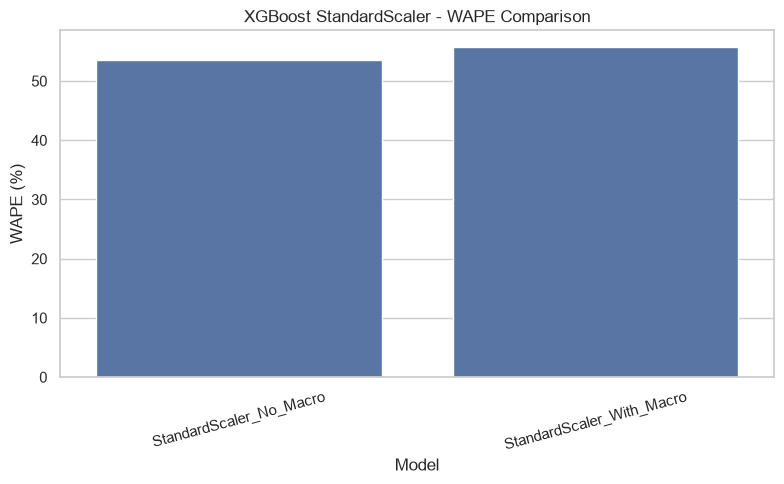

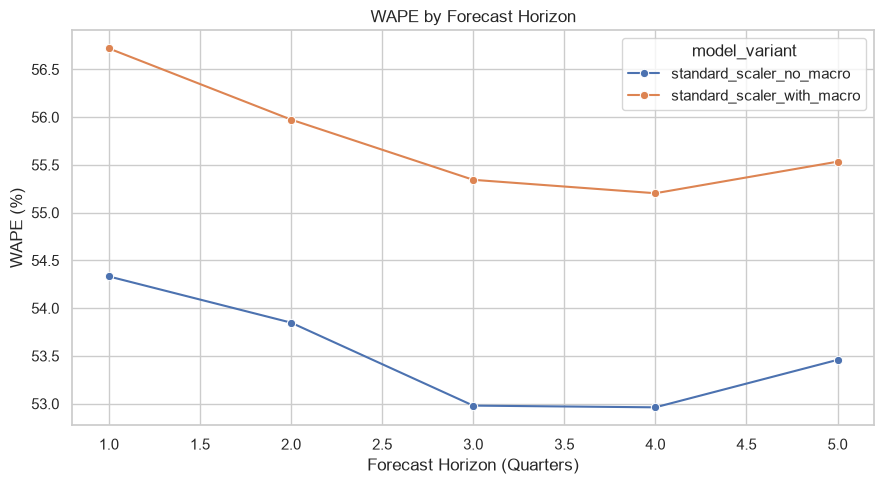

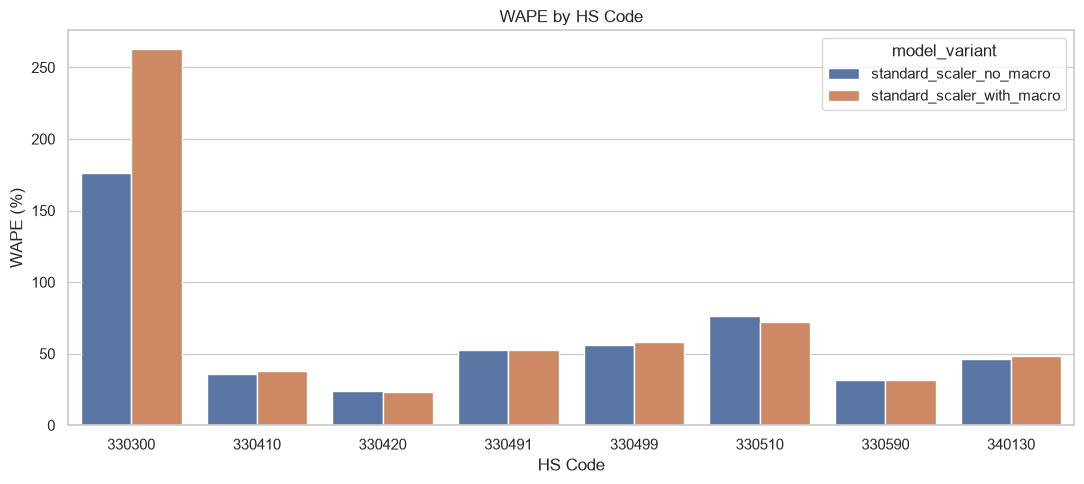

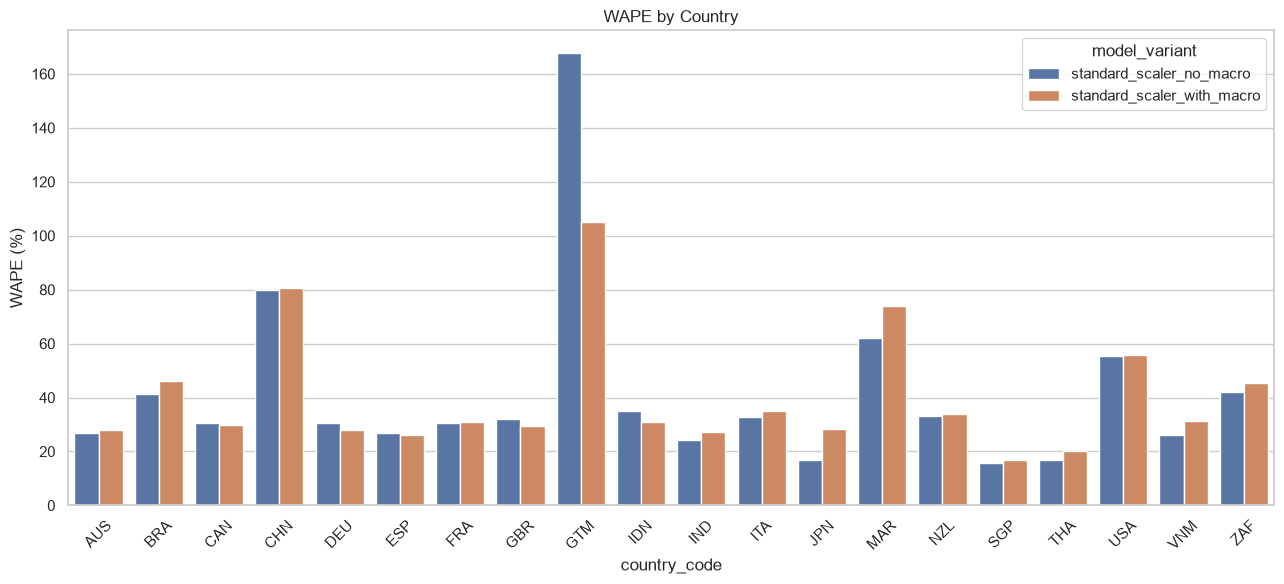

그래프 4개 저장 완료!
저장 위치: D:\hjs\five-stack\artifacts\xgboost\v002\standard_scaler\graphs


In [46]:

# STEP 11: XGBoost StandardScaler 그래프

import matplotlib.pyplot as plt
import seaborn as sns

GRAPH_DIR = OUT / "graphs"
GRAPH_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")

# 1. 거시지표 포함/제외 WAPE 비교
plt.figure(figsize=(8, 5))
sns.barplot(
    data=metrics_df,
    x="Model",
    y="WAPE (%)"
)
plt.title("XGBoost StandardScaler - WAPE Comparison")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(GRAPH_DIR / "01_wape_comparison.png", dpi=150)
plt.show()

# 2. 예측 기간별 WAPE
plt.figure(figsize=(9, 5))
sns.lineplot(
    data=horizon_metrics,
    x="horizon_quarters",
    y="WAPE (%)",
    hue="model_variant",
    marker="o"
)
plt.title("WAPE by Forecast Horizon")
plt.xlabel("Forecast Horizon (Quarters)")
plt.tight_layout()
plt.savefig(GRAPH_DIR / "02_horizon_wape.png", dpi=150)
plt.show()

# 3. 제품별 WAPE
plt.figure(figsize=(11, 5))
sns.barplot(
    data=product_metrics,
    x="hs_code",
    y="WAPE (%)",
    hue="model_variant"
)
plt.title("WAPE by HS Code")
plt.xlabel("HS Code")
plt.tight_layout()
plt.savefig(GRAPH_DIR / "03_product_wape.png", dpi=150)
plt.show()

# 4. 국가별 WAPE
plt.figure(figsize=(13, 6))
sns.barplot(
    data=country_metrics,
    x="country_code",
    y="WAPE (%)",
    hue="model_variant"
)
plt.title("WAPE by Country")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(GRAPH_DIR / "04_country_wape.png", dpi=150)
plt.show()

print("그래프 4개 저장 완료!")
print("저장 위치:", GRAPH_DIR)


In [47]:

# STEP 12: XGBoost 학습 모델 저장

import joblib

# 학습에 사용할 정답이 존재하는 데이터
final_train = train.loc[
    train[target].notna()
    & train["target_available"].fillna(False).astype(bool)
].copy()

# 1. 거시지표 제외 모델
final_model_no_macro = make_pipeline(
    features_no_macro,
    categorical
)

final_model_no_macro.fit(
    inputs(final_train, features_no_macro, categorical),
    final_train[target]
)

joblib.dump(
    {
        "model": final_model_no_macro,
        "feature_columns": features_no_macro,
        "categorical_columns": categorical,
        "target": target,
        "preprocessing": "StandardScaler",
        "macro": False,
        "dataset_version": manifest["dataset_version"]
    },
    OUT / "standard_scaler_no_macro.joblib"
)

print("거시지표 제외 모델 저장 완료!")

# 2. 거시지표 포함 모델
final_model_with_macro = make_pipeline(
    features_with_macro,
    categorical
)

final_model_with_macro.fit(
    inputs(final_train, features_with_macro, categorical),
    final_train[target]
)

joblib.dump(
    {
        "model": final_model_with_macro,
        "feature_columns": features_with_macro,
        "categorical_columns": categorical,
        "target": target,
        "preprocessing": "StandardScaler",
        "macro": True,
        "dataset_version": manifest["dataset_version"]
    },
    OUT / "standard_scaler_with_macro.joblib"
)

print("거시지표 포함 모델 저장 완료!")
print("저장 위치:", OUT)


거시지표 제외 모델 저장 완료!
거시지표 포함 모델 저장 완료!
저장 위치: D:\hjs\five-stack\artifacts\xgboost\v002\standard_scaler
